# 📘 Módulo 28: Reducción de Dimensiones I: PCA

Hola, deseamos darte la bienvenida al módulo **Reducción de Dimensiones I: PCA** del curso Profesión Científico de Datos.

En este módulo, exploraremos el **Análisis de Componentes Principales (PCA)**, una técnica esencial para la reducción de dimensionalidad en conjuntos de datos complejos. El PCA nos permite simplificar el análisis de datos con múltiples variables, extrayendo conclusiones más claras y facilitando su interpretación. 

### 🎯 Objetivos de Aprendizaje

1. **Fundamentos del PCA:**
   Aprenderemos sobre el origen y la utilidad del PCA en la ciencia de datos. Exploraremos cómo esta técnica permite condensar la información de un conjunto de datos en componentes principales que capturan la mayor cantidad de varianza posible.

2. **Implementación Práctica con Python y Arquitectura Modular:**
   Nos enfocaremos en la implementación utilizando Python, Scikit-learn y una arquitectura limpia separando scripts de ingeniería (`src/`) de los notebooks de storytelling (`notebooks/`).

3. **Análisis de Componentes y Varianza Explicada:**
   Profundizaremos en el cálculo de la varianza explicada, el uso de la matriz de correlaciones y la generación de mapas de observaciones y factores para identificar patrones subyacentes.

---

## 📁 Estructura del Repositorio en GitHub

Para mantener los estándares de ingeniería de software, este proyecto se estructura de la siguiente manera:

```text
28 - Reduccion de dimensiones I PCA/
│
├── data/
│   └── raw/
│       └── iris.csv         # Datos originales inmutables (150 registros)
│
├── src/
│   ├── __init__.py
│   └── pca_engine.py        # Clase modular PCAProcessor (estandarización + PCA)
│
├── notebooks/
│   └── 01_estudio_pca.ipynb # Libro de estudio visual y storytelling
│
├── app/
│   └── app.py               # Aplicación interactiva (Streamlit)
│
├── docs/
│   └── guia_estudio_pca_arquitectura.md
│
├── requirements.txt
├── .gitignore
└── README.md
```


In [1]:
# Configuración del path para permitir importaciones desde src/
import sys
from pathlib import Path

# Añadir directorio raíz del proyecto a sys.path
root_dir = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(root_dir) not in sys.path:
    sys.path.insert(0, str(root_dir))

# Importaciones para el Notebook de Storytelling
import logging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Importamos desde nuestra capa de ingeniería en src/
from src.pca_engine import PCAProcessor

# Configuración de estilos gráficos
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# La capa src/ solo emite logs; aquí decidimos mostrarlos
logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s')


In [2]:
# --- PASO 1: Carga del dataset Iris directamente desde la carpeta raw ---
data_path = root_dir / 'data' / 'raw' / 'iris.csv'
df_iris = pd.read_csv(data_path)

# Normalizamos los nombres de las columnas (reemplazando '.' por '_')
df_iris.columns = df_iris.columns.str.replace('.', '_', regex=False)

display(df_iris.head())
print(f"Dimensiones del dataset: {df_iris.shape}")


,sepal_length,sepal_width,petal_length,petal_width,variety
0,5.1,3.5,1.4,0.2,Setosa
1,4.9,3.0,1.4,0.2,Setosa
2,4.7,3.2,1.3,0.2,Setosa
3,4.6,3.1,1.5,0.2,Setosa
4,5.0,3.6,1.4,0.2,Setosa


Dimensiones del dataset: (150, 5)


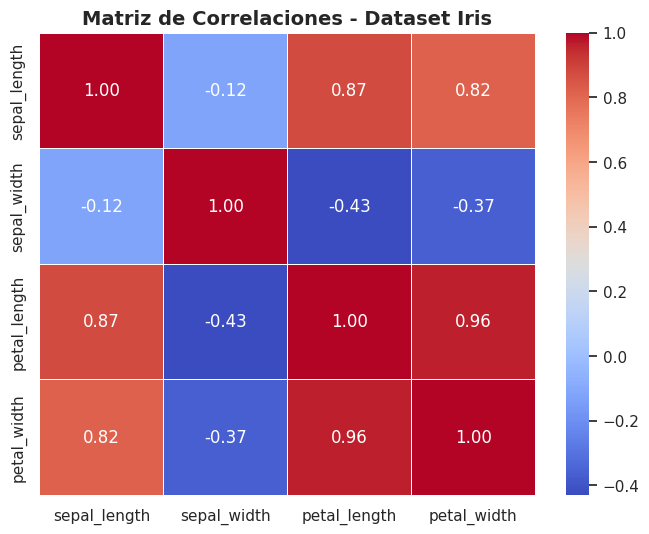

In [3]:
# --- PASO 2: Matriz de Correlaciones ---
# Es fundamental revisar la correlación previa para justificar el uso de PCA
plt.figure(figsize=(8, 6))
numeric_cols = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']
sns.heatmap(df_iris[numeric_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Matriz de Correlaciones - Dataset Iris", fontsize=14, fontweight='bold')
plt.show()

In [4]:
# --- PASO 3: Ejecución del PCA mediante nuestra clase modular ---
pca_engine = PCAProcessor(n_components=2)
X_pca = pca_engine.fit_transform(df_iris, numeric_cols)

# Agregamos las proyecciones al DataFrame para el análisis visual
df_iris['PC1'] = X_pca[:, 0]
df_iris['PC2'] = X_pca[:, 1]

# Verificamos la varianza explicada
var_exp = pca_engine.explained_variance_ratio_
print(f"\nVarianza explicada PC1: {var_exp[0]*100:.2f}%")
print(f"Varianza explicada PC2: {var_exp[1]*100:.2f}%")
print(f"Varianza total explicada con 2 componentes: {sum(var_exp)*100:.2f}%")

2026-10-23 19:24:28,039 - INFO - Iniciando transformación PCA con 2 componentes.


2026-10-23 19:24:28,045 - INFO - Varianza explicada acumulada: 95.81%



Varianza explicada PC1: 72.96%
Varianza explicada PC2: 22.85%
Varianza total explicada con 2 componentes: 95.81%


2026-10-23 19:24:28,059 - INFO - Iniciando transformación PCA con 4 componentes.


2026-10-23 19:24:28,064 - INFO - Varianza explicada acumulada: 100.00%


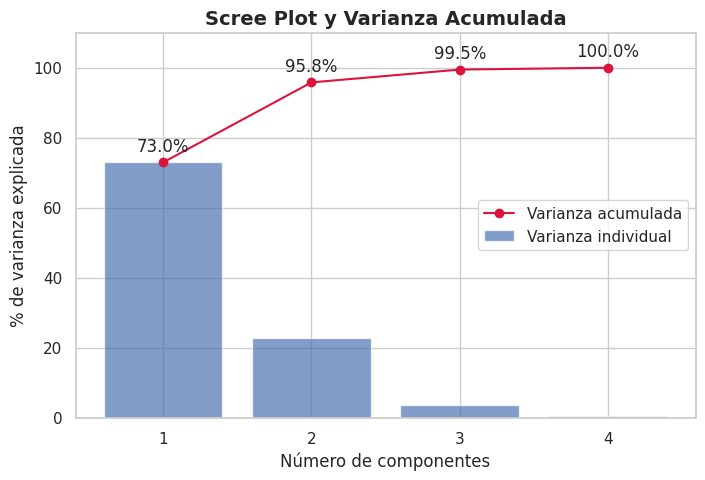

In [5]:
# --- Justificación de k: scree plot y varianza acumulada con los 4 componentes ---
pca_full = PCAProcessor(n_components=4)
pca_full.fit_transform(df_iris, numeric_cols)
ratios = pca_full.explained_variance_ratio_
cumulative = np.cumsum(ratios)

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(range(1, 5), ratios * 100, alpha=0.7, label='Varianza individual')
ax.plot(range(1, 5), cumulative * 100, marker='o', color='crimson', label='Varianza acumulada')
for i, c in enumerate(cumulative, start=1):
    ax.annotate(f'{c*100:.1f}%', (i, c * 100), textcoords='offset points', xytext=(0, 8), ha='center')
ax.set_xticks(range(1, 5))
ax.set_xlabel('Número de componentes')
ax.set_ylabel('% de varianza explicada')
ax.set_ylim(0, 110)
ax.set_title('Scree Plot y Varianza Acumulada', fontsize=14, fontweight='bold')
ax.legend()
plt.show()


### 💡 Análisis del Grado de Explicación de la Varianza
Al utilizar los dos primeros componentes principales (PC1 y PC2), capturamos aproximadamente **95.81% de la varianza total** del conjunto de datos original de 4 dimensiones. Esto significa que podemos pasar de 4 variables a solo 2 dimensiones perdiendo menos del 5% de la información global (la varianza descartada es información de menor peso, no necesariamente ruido).

Para justificar la elección de **k = 2** en lugar de asumirla, en la siguiente celda ajustamos los 4 componentes y revisamos el *scree plot* y la varianza acumulada.

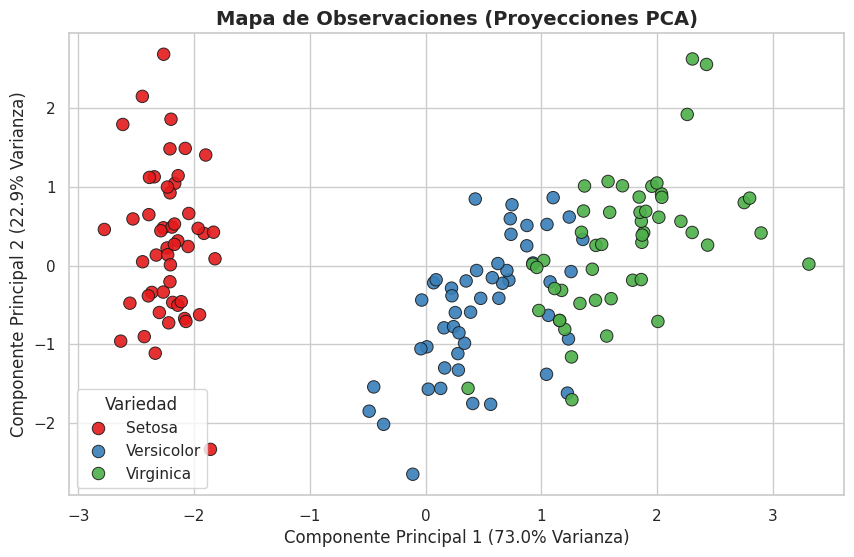

In [6]:
# --- PASO 4: Visualización del Mapa de Observaciones ---
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x='PC1', y='PC2', 
    hue='variety', 
    data=df_iris, 
    palette='Set1', 
    s=80, 
    alpha=0.9,
    edgecolor='k'
)
plt.title('Mapa de Observaciones (Proyecciones PCA)', fontsize=14, fontweight='bold')
plt.xlabel(f'Componente Principal 1 ({var_exp[0]*100:.1f}% Varianza)')
plt.ylabel(f'Componente Principal 2 ({var_exp[1]*100:.1f}% Varianza)')
plt.legend(title='Variedad')
plt.show()

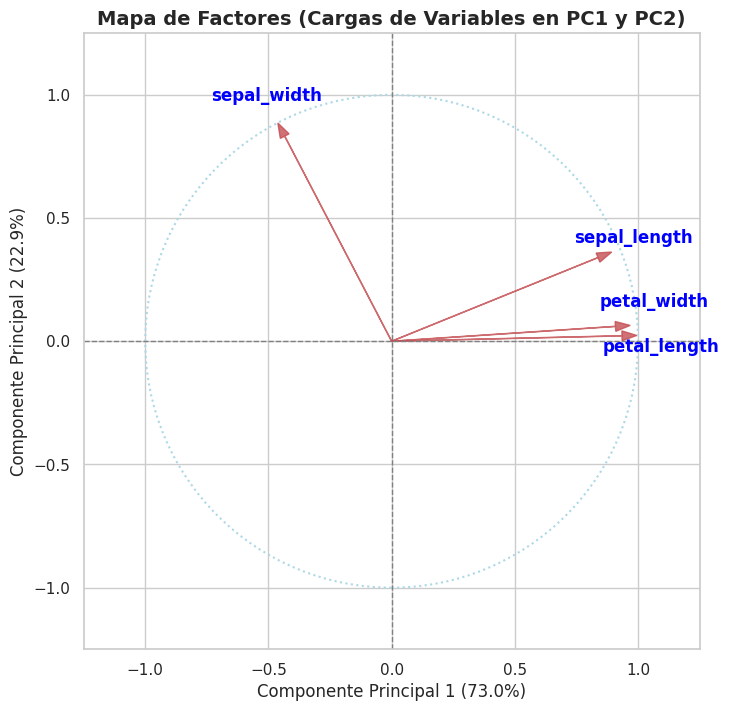

,sepal_length,sepal_width,petal_length,petal_width
PC1,0.893,-0.462,0.995,0.968
PC2,0.362,0.886,0.023,0.064


In [7]:
# --- PASO 5: Mapa de Factores (Círculo de Correlación) ---
# Se grafican las CARGAS (correlación variable-componente), no los eigenvectores crudos:
# así el círculo unitario es válido y la longitud de la flecha indica representatividad.
loadings = pca_engine.get_loadings()

fig, ax = plt.subplots(figsize=(8, 8))
ax.axhline(0, color='grey', linestyle='--', linewidth=1)
ax.axvline(0, color='grey', linestyle='--', linewidth=1)
ax.add_artist(plt.Circle((0, 0), 1.0, color='lightblue', fill=False, linestyle=':', linewidth=1.5))

label_offsets = {'petal_width': (0, 0.07), 'petal_length': (0, -0.07)}
for feature in loadings.columns:
    x, y = loadings.loc['PC1', feature], loadings.loc['PC2', feature]
    ax.arrow(0, 0, x, y, color='r', alpha=0.8, head_width=0.04, head_length=0.06, length_includes_head=True)
    dx, dy = label_offsets.get(feature, (0, 0))  # separa etiquetas que se encimarían
    ax.text(x * 1.1 + dx, y * 1.1 + dy, feature, color='blue', fontsize=12, fontweight='bold', ha='center')

ax.set_xlim(-1.25, 1.25)
ax.set_ylim(-1.25, 1.25)
ax.set_aspect('equal')
ax.set_title('Mapa de Factores (Cargas de Variables en PC1 y PC2)', fontsize=14, fontweight='bold')
ax.set_xlabel(f'Componente Principal 1 ({var_exp[0]*100:.1f}%)')
ax.set_ylabel(f'Componente Principal 2 ({var_exp[1]*100:.1f}%)')
ax.grid(True)
plt.show()

display(loadings.round(3))


### 🔍 Conclusiones de la Comparación (Mapa de Observaciones vs. Mapa de Factores)

1. **Relación Directa:** Al cruzar el mapa de factores con el mapa de observaciones, se observa que variables como `petal_length` y `petal_width` apuntan fuertemente en la dirección del eje PC1. Esto explica por qué la variedad *Setosa* se separa de forma tan limpia y radical hacia un extremo del componente 1.
2. **Corrobora Casos Específicos:** Las flores con longitudes de pétalo muy pequeñas corresponden al clúster aislado de *Setosa* en el mapa de observaciones. Ojo: *Versicolor* y *Virginica* se solapan en el plano PC1-PC2, y el PCA descarta un 4.2% de la varianza, por lo que la proyección simplifica la realidad, no la reproduce de forma exacta.
3. **Ventaja Analítica:** El mapa de factores nos permite entender *qué variables están impulsando* las agrupaciones que vemos en el mapa de observaciones, facilitando la explicabilidad del modelo ante stakeholders de negocio.

---

## 🚀 Mentalidad End-to-End: Implementación del Modelo

> **Aplicación Interactiva Implementada con Streamlit (`app/app.py`):**
>
> Se ha construido la aplicación web interactiva en `app/app.py`. Esta herramienta permite a los analistas de negocio y biólogos:
> - **Ingresar mediciones en tiempo real:** Ajustar las 4 variables biométricas mediante deslizadores (*sliders*) interactivos o plantillas predefinidas.
> - **Transformación con la capa de ingeniería:** La app reutiliza directamente la clase `PCAProcessor` de `src/pca_engine.py`, aplicando el pipeline de estandarización y proyección entrenado (`.transform()`).
> - **Proyección dinámica y proximidad a clústeres:** Ubica un marcador en vivo sobre el mapa de observaciones y calcula la distancia euclidiana hacia los centroides para orientar a qué variedad de Iris se asemeja la muestra (clasificación por centroide más cercano: usa las etiquetas, a diferencia del PCA, que es no supervisado).
> - **Explicabilidad factorial:** Incluye el mapa de cargas de variables y KPIs de varianza acumulada (95.81%).
>
> **Comando de ejecución:**
> ```bash
> streamlit run app/app.py
> ```

---

## 📚 Glosario (Módulo 28)

* **Componentes principales:** Variables derivadas que capturan la mayor cantidad de varianza posible de los datos originales, permitiendo una representación simplificada del conjunto de datos.
* **Eigenvectores:** Vectores que representan la dirección de los componentes principales en el espacio de datos, fundamentales para la transformación de PCA.
* **Explained variance ratio:** Porcentaje que indica cuánta de la variabilidad total de los datos es capturada por cada componente principal, ayudando a decidir cuántos componentes retener.
* **Matriz de correlaciones:** Matriz que muestra las relaciones lineales entre las variables originales, crucial para identificar patrones antes de aplicar PCA.
* **Mapa de factores:** Representación visual que muestra cómo las variables originales se relacionan en el nuevo espacio de componentes, facilitando la interpretación de correlaciones.
* **Pipeline:** Secuencia de pasos de procesamiento de datos que incluye la estandarización y la aplicación de PCA, automatizando el flujo de trabajo de análisis.
* **Proyecciones de componentes:** Transformaciones de los datos originales en el espacio de componentes principales, utilizadas para visualizar y analizar patrones subyacentes.
* **Reducción de dimensionalidad:** Proceso de simplificar un conjunto de datos con muchas variables a un conjunto con menos variables, manteniendo la mayor cantidad de información posible.
* **Scikit-learn:** Biblioteca de Python utilizada para implementar PCA y otras técnicas de aprendizaje automático, proporcionando herramientas para el análisis de datos.
* **StandardScaler:** Módulo de Scikit-learn que estandariza las variables antes de aplicar PCA, asegurando que cada variable contribuya igualmente al análisis.